### Installing required libraries

In [1]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars


### Importing all libraries 

In [2]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [3]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [4]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [5]:
print(diabetes.columns)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')


In [6]:
for g in diabetes['gender'].unique():
    col = f"Gender_{g}"
    diabetes[col] = (diabetes['gender'] == g).astype(int)


In [7]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [8]:
# Mapping Admission Type ID to interpretable binary categories:
# 1 = Emergency/Urgent/Trauma
# 0 = Elective/Newborn/NotAvailable/NULL/NotMapped

admission_type_binary_map = {
    1: 1,  # Emergency
    2: 1,  # Urgent
    7: 1,  # TraumaCenter

    3: 0,  # Elective
    4: 0,  # Newborn
    5: 0,  # NotAvailable
    6: 0,  # NULL
    8: 0   # NotMapped
}

diabetes["admission_emergency"] = (
    diabetes["admission_type_id"]
    .map(admission_type_binary_map)
    .fillna(0)
    .astype(int)
)


In [9]:
# Binary mapping for discharge disposition:
# 0 = routine / lower‑risk discharge
# 1 = adverse / higher‑risk discharge

discharge_disposition_binary_map = {
    # lower‑risk / routine
    2: 0,   # ShortTermHospital
    11: 0,  # Expired
    12: 0,  # StillPatient
    13: 0,  # HospiceHome   
    14: 0,  # HospiceFacility
    15: 0,  # SwingBed
    19: 0,  # ExpiredHomeMedicaid
    20: 0,  # ExpiredFacilityMedicaid
    21: 0,  # ExpiredUnknownMedicaid
   
    # posible higher‑risk / adverse outcomes
    1: 1,   # Home
    3: 1,   # SNF
    4: 1,   # ICF
    5: 1,   # OtherInpatientCare
    6: 1,   # HomeHealth
    7: 1,   # LeftAMA
    8: 1,   # HomeIVCare
    9: 1,   # AdmittedToThisHospital
    10: 1,  # NeonateToAnotherHospital
    16: 1,  # OutpatientServicesOtherInstitution
    17: 1,  # OutpatientServicesThisInstitution
    18: 1,  # NULL
    22: 1,  # RehabFacility
    23: 1,  # LongTermCareHospital
    24: 1,  # MedicaidNursingFacility
    25: 1,  # NotMapped
    27: 1,  # FederalHealthCareFacility
    28: 1,  # PsychiatricHospital
    29: 1,  # CriticalAccessHospital
    30: 1,   # OtherHealthcareInstitution
    
}

diabetes["DischargeRisk"] = (
    diabetes["discharge_disposition_id"]
        .map(discharge_disposition_binary_map)
        .fillna(0)
        .astype(int)
)


In [10]:
def icd_to_chapter(code):
    # Handle missing or non-numeric codes
    try:
        code = float(code)
    except:
        return "Unknown"

    if 1 <= code <= 139:
        return "Infectious and Parasitic Diseases"
    elif 140 <= code <= 239:
        return "Neoplasms"
    elif 240 <= code <= 279:
        return "Endocrine/Metabolic"
    elif 280 <= code <= 289:
        return "Blood Diseases"
    elif 290 <= code <= 319:
        return "Mental Disorders"
    elif 320 <= code <= 389:
        return "Nervous System"
    elif 390 <= code <= 459:
        return "Circulatory System"
    elif 460 <= code <= 519:
        return "Respiratory System"
    elif 520 <= code <= 579:
        return "Digestive System"
    elif 580 <= code <= 629:
        return "Genitourinary System"
    elif 630 <= code <= 679:
        return "Pregnancy/Childbirth"
    elif 680 <= code <= 709:
        return "Skin/Subcutaneous"
    elif 710 <= code <= 739:
        return "Musculoskeletal"
    elif 740 <= code <= 759:
        return "Congenital Anomalies"
    elif 760 <= code <= 779:
        return "Perinatal Conditions"
    elif 780 <= code <= 799:
        return "Symptoms/Ill-defined"
    elif 800 <= code <= 999:
        return "Injury/Poisoning"
    elif code >= 1000:
        return "Unknown"
    else:
        return "Unknown"


In [11]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_chapter"] = diabetes[col].apply(icd_to_chapter)


In [12]:
# ============================================================
# Binary mapping for ICD diagnosis chapters
# ============================================================
diag_binary_map = {
    "Endocrine/Metabolic": 1,
    "Circulatory System": 1,
    "Respiratory System": 1,
    "Neoplasms": 1,
    "Infectious and Parasitic Diseases": 1,
    "Injury/Poisoning": 1,
    "Genitourinary System": 1,
    "Nervous System": 1,
    "Blood Diseases": 1,
    "Mental Disorders": 1,

    "Symptoms/Ill-defined": 0,
    "Skin/Subcutaneous": 0,
    "Musculoskeletal": 0,
    "Digestive System": 0,
    "Pregnancy/Childbirth": 0,
    "Congenital Anomalies": 0,
    "V-Codes": 0,
    "E-Codes": 0,
    "Unknown": 0
}

for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = (
        diabetes[col]
            .map(diag_binary_map)
            .fillna(0)
            .astype(int)
    )


In [13]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 1 if str(x).strip().lower() == "yes" else 0
)

In [ ]:
# Ensure A1Cresult is treated as string
diabetes['A1Cresult'] = diabetes['A1Cresult'].astype(str)

# 1. Remove rows where A1Cresult is None, 'None', empty, or NaN
# diabetes = diabetes[
#    (diabetes['A1Cresult'].notna()) &
#    (diabetes['A1Cresult'].str.strip() != "None") &
#    (diabetes['A1Cresult'].str.strip() != "")
#]

# Create one-hot encoded columns for each unique A1Cresult value
for val in diabetes['A1Cresult'].unique():
    col = f"A1C_{val}"
    diabetes[col] = (diabetes['A1Cresult'] == val).astype(int)


In [15]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# lessthan30 = 1 if readmitted is "<30", else 0

diabetes['lessthan30'] = (diabetes['readmitted'] == '<30').astype(int)

In [16]:
#@title RACE ENCODING
# Replace '?' with 'Unknown'
diabetes['race'] = diabetes['race'].replace('?', 'Unknown')

# Create binary columns for each race category
for race in diabetes['race'].unique():
    col_name = f"Race_{race}"
    diabetes[col_name] = (diabetes['race'] == race).astype(int)


In [17]:
diabetes.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'Gender_Female', 'Gender_Male', 'Gender_Unknown/Invalid',
       'admission_emergency

In [18]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'encounter_id', 'patient_nbr', 'race', 'gender', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'payer_code', 'medical_specialty', 'diag_1',
       'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted'
], axis=1)

In [19]:
print(cleandiabetes.columns)

Index(['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'number_diagnoses', 'diabetesMed', 'Gender_Female',
       'Gender_Male', 'Gender_Unknown/Invalid', 'admission_emergency',
       'DischargeRisk', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter',
       'A1C_nan', 'A1C_>7', 'A1C_>8', 'A1C_Norm', 'lessthan30',
       'Race_Caucasian', 'Race_AfricanAmerican', 'Race_Unknown', 'Race_Other',
       'Race_Asian', 'Race_Hispanic'],
      dtype='str')


In [20]:
numerical = [ 'age' , 'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_emergency',
    'number_outpatient',
    'number_inpatient',
    'number_diagnoses' ]

### MISSING DATA

In [21]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [22]:
print("Missing Data in Sub1:")
display(missing(cleandiabetes))



Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
number_outpatient,0,0.0
number_emergency,0,0.0
number_inpatient,0,0.0
number_diagnoses,0,0.0
diabetesMed,0,0.0


### CORRELATION

In [23]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(cleandiabetes[numerical].corr())

Correlation Matrix for Sub1


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_emergency,number_outpatient,number_inpatient,number_diagnoses
age,1.000000,0.107515,0.020770,-0.030104,0.041847,-0.087291,0.023724,-0.042861,0.242597
time_in_hospital,0.107515,1.000000,0.318450,0.191472,0.466135,-0.009681,-0.008916,0.073623,0.220186
num_lab_procedures,0.020770,0.318450,1.000000,0.058066,0.268161,-0.002279,-0.007602,0.039231,0.152773
num_procedures,-0.030104,0.191472,0.058066,1.000000,0.385767,-0.038179,-0.024819,-0.066236,0.073734
num_medications,0.041847,0.466135,0.268161,0.385767,1.000000,0.013180,0.045197,0.064194,0.261526
number_emergency,-0.087291,-0.009681,-0.002279,-0.038179,0.013180,1.000000,0.091459,0.266559,0.055539
number_outpatient,0.023724,-0.008916,-0.007602,-0.024819,0.045197,0.091459,1.000000,0.107338,0.094152
number_inpatient,-0.042861,0.073623,0.039231,-0.066236,0.064194,0.266559,0.107338,1.000000,0.104710
number_diagnoses,0.242597,0.220186,0.152773,0.073734,0.261526,0.055539,0.094152,0.104710,1.000000


In [24]:
print("Correlation for lessthan30 grouped by readmit_less_30")
display(cleandiabetes.groupby('lessthan30')[numerical].corr())


Correlation for lessthan30 grouped by readmit_less_30


age  time_in_hospital  num_lab_procedures  \
lessthan30                                                                      
0          age                 1.000000          0.110387            0.023671   
           time_in_hospital    0.110387          1.000000            0.317989   
           num_lab_procedures  0.023671          0.317989            1.000000   
           num_procedures     -0.030476          0.184408            0.052895   
           num_medications     0.045641          0.463444            0.263560   
           number_emergency   -0.073727         -0.003926            0.004755   
           number_outpatient   0.025838         -0.008024           -0.009675   
           number_inpatient   -0.012445          0.081368            0.044145   
           number_diagnoses    0.250573          0.222780            0.153492   
1          age                 1.000000          0.078964           -0.006361   
           time_in_hospital    0.078964          1.000000            0.317655   
           num_lab_procedures -0.006361          0.317655            1.000000   
           num_procedures     -0.025012          0.256572            0.104734   
           num_medications     0.005392          0.479381            0.300945   
           number_emergency   -0.171721         -0.054951           -0.046064   
           number_outpatient   0.004394         -0.022948            0.005296   
           number_inpatient   -0.209974          0.011970            0.004974   
           number_diagnoses    0.167476          0.182704            0.138825   

                               num_procedures  num_medications  \
lessthan30                                                       
0          age                      -0.030476         0.045641   
           time_in_hospital          0.184408         0.463444   
           num_lab_procedures        0.052895         0.263560   
           num_procedures            1.000000         0.385410   
           num_medications           0.385410         1.000000   
           number_emergency         -0.036945         0.017058   
           number_outpatient        -0.023123         0.044063   
           number_inpatient         -0.063114         0.066989   
           number_diagnoses          0.071852         0.261229   
1          age                      -0.025012         0.005392   
           time_in_hospital          0.256572         0.479381   
           num_lab_procedures        0.104734         0.300945   
           num_procedures            1.000000         0.396435   
           num_medications           0.396435         1.000000   
           number_emergency         -0.044692        -0.019015   
           number_outpatient        -0.036554         0.048016   
           number_inpatient         -0.084559         0.028102   
           number_diagnoses          0.098215         0.251496   

                               number_emergency  number_outpatient  \
lessthan30                                                           
0          age                        -0.073727           0.025838   
           time_in_hospital           -0.003926          -0.008024   
           num_lab_procedures          0.004755          -0.009675   
           num_procedures             -0.036945          -0.023123   
           num_medications             0.017058           0.044063   
           number_emergency            1.000000           0.091215   
           number_outpatient           0.091215           1.000000   
           number_inpatient            0.241279           0.106598   
           number_diagnoses            0.056901           0.093659   
1          age                        -0.171721           0.004394   
           time_in_hospital           -0.054951          -0.022948   
           num_lab_procedures         -0.046064           0.005296   
           num_procedures             -0.044692          -0.036554   
           num_medications            -0.019

In [25]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


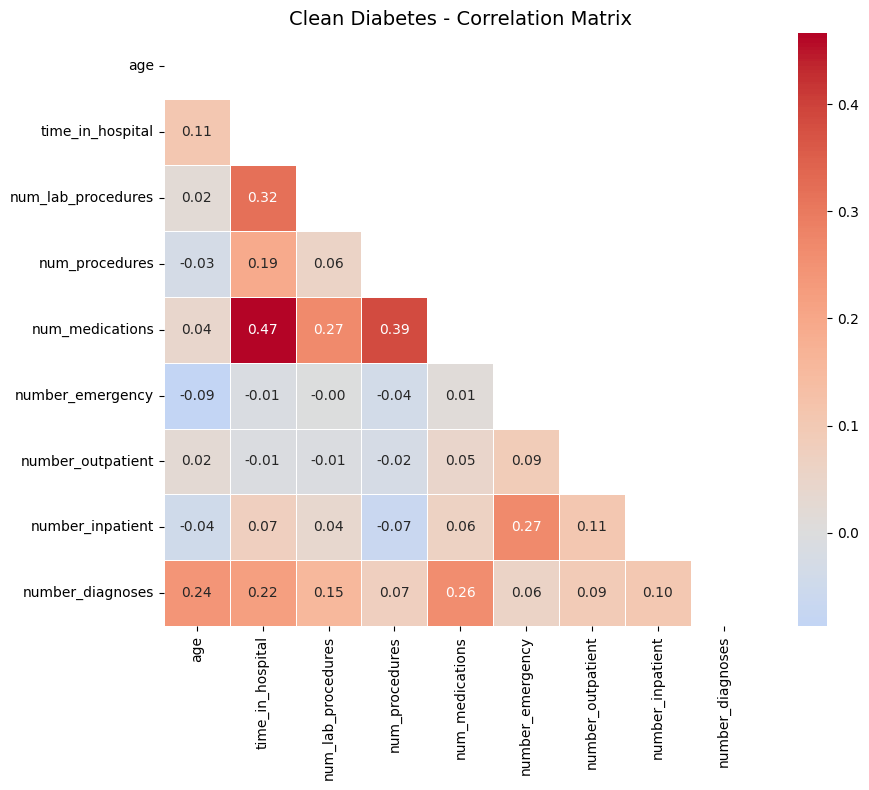

In [26]:
plot_corr_heatmap(cleandiabetes, numerical, "Clean Diabetes - Correlation Matrix")


## Breaking the data up into Train & Test

In [27]:
#@title Setting Up Data for Modeling 
#Uses the cleandiabetes dataset for modeling.
DataTesting = cleandiabetes.copy() #change it to sub2 or Sub3 to test each dataset

In [28]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71236
Validation size: 15265
Test size: 15265
Total: 101766


In [29]:
DataTesting.lessthan30.value_counts()

lessthan30
0    90409
1    11357
Name: count, dtype: int64

In [30]:
train_df.lessthan30.value_counts()

lessthan30
0    63304
1     7932
Name: count, dtype: int64

In [31]:
valid_df.lessthan30.value_counts()

lessthan30
0    13500
1     1765
Name: count, dtype: int64

In [32]:
test_df.lessthan30.value_counts()

lessthan30
0    13605
1     1660
Name: count, dtype: int64

## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [33]:
def balance_random_oversample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [34]:
def balance_smote(df, target='readmit_less_30', random_state=42):
    X = df.drop(columns=[target])
    y = df[target]

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal

#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [35]:
def balance_random_undersample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 4. SMOTEENN


In [36]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE

def apply_smoteenn(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTEENN hybrid resampling:
    - SMOTE oversamples the minority class
    - ENN removes noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_enn = SMOTEENN(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_enn.fit_resample(X, y)
    return X_resampled, y_resampled

#### 5. SMOTETOMEK

In [37]:
from imblearn.combine import SMOTETomek

def apply_smotetomek(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTETomek hybrid resampling:
    - SMOTE oversamples the minority class
    - Tomek Links remove borderline/noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_tomek = SMOTETomek(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
    return X_resampled, y_resampled


#### Prevalence Caculation Function

In [38]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

<h2 style="color:#e63946;">CHANGE THE IMBALANCE TECHNIQUE HERE</h2>
“Remove the # to activate a specific technique."


In [39]:
# 1. Split train_df into X and y
X_train = train_df.drop(columns=["lessthan30"])
y_train = train_df["lessthan30"]

# 2. Apply SMOTEENN
X_bal, y_bal = apply_smoteenn(X_train, y_train)

# 3. Combine back into a single DataFrame (optional)
train_balanced = X_bal.copy()
train_balanced["lessthan30"] = y_bal

# 4. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['lessthan30']))
)


Train balanced prevalence (n = 90896): 0.642


In [40]:
train_balanced.lessthan30.value_counts()

lessthan30
1    58351
0    32545
Name: count, dtype: int64

In [41]:
X_train = train_balanced.drop('lessthan30',axis=1)

y_train = train_balanced['lessthan30']

X_valid = valid_df.drop('lessthan30',axis=1)

y_valid = valid_df['lessthan30']

X_test = test_df.drop('lessthan30',axis=1)

y_test = test_df['lessthan30']

<h2 style="color:#e63946;">CHANGE THE SETS HERE FOR SCALER</h2>

In [42]:
scale_cols = numerical
# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [43]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,...,A1C_nan,A1C_>7,A1C_>8,A1C_Norm,Race_Caucasian,Race_AfricanAmerican,Race_Unknown,Race_Other,Race_Asian,Race_Hispanic
0,1.193094,1.949210,0.073468,-0.722701,-0.275336,-0.257205,-0.191018,-0.508753,0.856634,1,...,0,0,0,0,1,0,0,0,0,0
1,1.193094,-1.157992,-0.337058,0.545629,-1.146169,-0.257205,-0.191018,-0.508753,-1.316322,0,...,0,0,0,0,1,0,0,0,0,0
2,-0.059611,1.258721,0.073468,-0.722701,0.968710,-0.257205,0.816923,2.247740,0.856634,1,...,0,0,0,0,1,0,0,0,0,0
3,-0.059611,2.639699,0.381362,-0.722701,-0.524146,-0.257205,-0.191018,-0.508753,-0.229844,1,...,0,0,0,0,1,0,0,0,0,0
4,-0.059611,-0.122258,-1.260740,3.082291,-0.150932,-0.257205,-0.191018,-0.508753,0.313395,1,...,0,0,0,0,1,0,0,0,0,0


## Creating and Understanding Models

In [44]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [45]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [46]:
print(y_valid_preds)

[ 6.17149521e-01  5.41790194e-01  3.69064532e-01  1.81374691e-01
  4.24565101e-01  6.22984751e-01  5.80036571e-01  5.89162634e-01
  3.61913648e-01  5.37844709e-01  5.04748850e-01  3.12793696e-01
  2.81024525e-01  5.78370482e-01  2.43505503e-01  4.04150055e-01
  5.00635207e-01  4.24839040e-01  3.88389948e-01  4.81372047e-01
  5.88270277e-01  4.57101042e-01  6.39092960e-01  5.02969943e-01
  5.34770871e-01  6.29328372e-01  3.39076159e-01  6.80886784e-01
  7.39889583e-01  6.27379517e-01  5.16759332e-01  3.12442815e-01
  3.97514408e-01  3.38534401e-01  5.06669674e-01  7.33518643e-01
  5.70973921e-01  6.25838263e-01  5.27236593e-01  6.01560214e-01
  3.03515947e-01  6.16225505e-01  5.44085093e-01 -7.91771663e-03
  5.49297427e-01  4.76839788e-01  2.66145374e-01  4.76064970e-01
  1.80992883e-01  4.04445066e-01  4.33843272e-01  7.16870560e-01
  6.22416196e-01  4.49746135e-01  2.52549518e-01  5.84732887e-01
 -2.36785347e-01  1.78559135e-01  2.83939324e-01  7.51363922e-01
  4.39842578e-01  2.38341

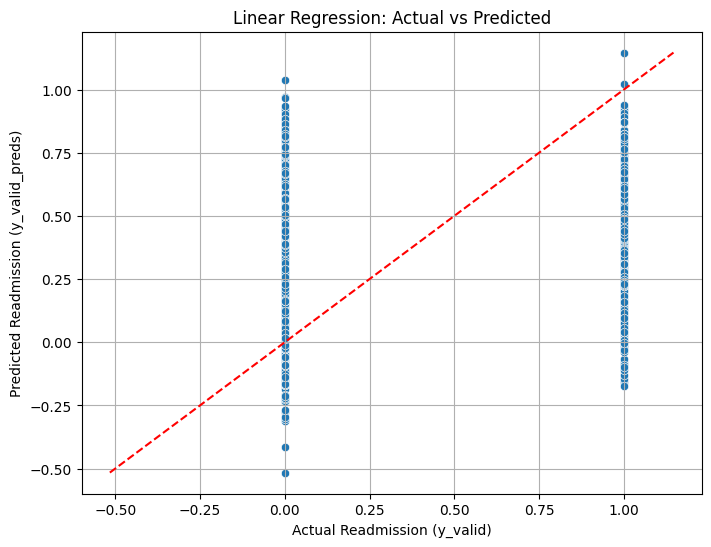

In [47]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


### Logistic Regression

In [48]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.564
accuracy:0.658
recall:0.390
precision:0.142
specificity:0.693
prevalence:0.116
 


### KNN Model

In [49]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.576
accuracy:0.495
recall:0.611
precision:0.133
specificity:0.460
prevalence:0.116
 


### Stochastic Gradient Descent Model

In [50]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.576
accuracy:0.239
recall:0.893
precision:0.121
specificity:0.154
prevalence:0.116
 


### Decision Tree

In [51]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.557
accuracy:0.612
recall:0.433
precision:0.134
specificity:0.632
prevalence:0.116
 


### Random Forest

In [52]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 6)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.555
accuracy:0.379
recall:0.731
precision:0.125
specificity:0.333
prevalence:0.116
 


### Linear SVC

In [53]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.564
accuracy:0.866
recall:0.069
precision:0.234
specificity:0.971
prevalence:0.116
 


### Gradient Boosting Model

In [54]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.573
accuracy:0.672
recall:0.377
precision:0.145
specificity:0.710
prevalence:0.116
 


### XGB Model

In [55]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.573
accuracy:0.679
recall:0.372
precision:0.148
specificity:0.719
prevalence:0.116
 


### Catboost Model

In [56]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.5205415	total: 163ms	remaining: 32.4s
1:	learn: 0.4858082	total: 168ms	remaining: 16.6s
2:	learn: 0.4682608	total: 172ms	remaining: 11.3s
3:	learn: 0.4488264	total: 177ms	remaining: 8.66s
4:	learn: 0.4363851	total: 181ms	remaining: 7.08s
5:	learn: 0.4234009	total: 186ms	remaining: 6.02s
6:	learn: 0.4130332	total: 190ms	remaining: 5.25s
7:	learn: 0.4050699	total: 195ms	remaining: 4.68s
8:	learn: 0.3993307	total: 201ms	remaining: 4.26s
9:	learn: 0.3943564	total: 205ms	remaining: 3.9s
10:	learn: 0.3908524	total: 210ms	remaining: 3.61s
11:	learn: 0.3882935	total: 216ms	remaining: 3.38s
12:	learn: 0.3865251	total: 221ms	remaining: 3.17s
13:	learn: 0.3848751	total: 224ms	remaining: 2.98s
14:	learn: 0.3825380	total: 229ms	remaining: 2.83s
15:	learn: 0.3805965	total: 235ms	remaining: 2.7s
16:	learn: 0.3767984	total: 239ms	remaining: 2.57s
17:	learn: 0.3754127	total: 244ms	remaining: 2.47s
18:	learn: 0.3744200	total: 249ms	remaining: 2.37s
19:	learn: 0.3729726	total: 254ms	remaining

## Hyper Parameter Tuning

### Decision Tree

In [57]:
# Decision Tree - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'min_samples_leaf': range(1, 11, 2), ###  -->> Added a critical param
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid,
                               n_iter = 20,
                               cv = 10,              ### -->> chnaged cv from 2 to 5
                               scoring ='recall',   ### -->> changed fromscoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

# added later
print("Best params:", dc_random.best_params_)
print("Best CV recall:", dc_random.best_score_)
print("Validation recall:", recall_score(y_valid, dc_random.best_estimator_.predict(X_valid)))

"""
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.8327703475995127
Validation recall: 0.996244131455399

add all metrics from above
"""

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best params: {'min_samples_split': 8, 'min_samples_leaf': 9, 'max_features': 'sqrt', 'max_depth': 3, 'criterion': 'gini'}
Best CV recall: 0.9763326761236728
Validation recall: 0.884985835694051


"\nFitting 5 folds for each of 20 candidates, totalling 100 fits\nBest params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}\nBest CV recall: 0.8327703475995127\nValidation recall: 0.996244131455399\n\nadd all metrics from above\n"

In [58]:

recall_score(y_valid, dc_hp_preds)

0.884985835694051

### Random Forest

In [59]:
# Random Forest - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid,
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.5279421466792571

In [60]:

recall_score(y_valid, dc_hp_preds)

0.884985835694051

### XGBoost

In [61]:
#xgboost - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid,
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.5710573916692897

In [62]:

recall_score(y_valid, dc_hp_preds)

0.884985835694051

#### 4. SAVING PKL MODEL

In [63]:
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score, confusion_matrix

# ============================================================
# TARGET
# ============================================================
target = "lessthan30"

print("\n" + "="*70)
print(f"     RANDOM FOREST — FINAL MODEL ({target.upper()}) ")
print("="*70)

prev = y_valid.mean()

# ============================================================
# TRAIN RANDOM FOREST
# ============================================================
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_split=2,
    random_state=111,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# ============================================================
# PREDICT PROBABILITIES
# ============================================================
preds_proba = rf.predict_proba(X_valid)[:, 1]

# ============================================================
# METRICS
# ============================================================
auc = roc_auc_score(y_valid, preds_proba)

preds = (preds_proba >= 0.5).astype(int)

acc = accuracy_score(y_valid, preds)
rec = recall_score(y_valid, preds)
prec = precision_score(y_valid, preds)

tn, fp, fn, tp = confusion_matrix(y_valid, preds).ravel()
spec = tn / (tn + fp)

# ============================================================
# PRINT RESULTS
# ============================================================
print("\nValidation Metrics (Random Forest):")
print("-"*50)
print(f"AUC:          {auc:.4f}")
print(f"Accuracy:     {acc:.4f}")
print(f"Recall:       {rec:.4f}")
print(f"Precision:    {prec:.4f}")
print(f"Specificity:  {spec:.4f}")
print(f"Prevalence:   {prev:.4f}")
print("="*70)

# ============================================================
# SAVE MODEL
# ============================================================
filename = f"{target}_RandomForest_Final.Smoteenn.a1c.pkl"
joblib.dump(rf, filename)

print(f"Saved Random Forest model as '{filename}'")
print("="*70 + "\n")

final_models = {target: rf}



     RANDOM FOREST — FINAL MODEL (LESSTHAN30) 

Validation Metrics (Random Forest):
--------------------------------------------------
AUC:          0.5545
Accuracy:     0.3792
Recall:       0.7309
Precision:    0.1253
Specificity:  0.3332
Prevalence:   0.1156
Saved Random Forest model as 'lessthan30_RandomForest_Final.Smoteenn.a1c.pkl'

